# Experiment 10: Ensemble Learning (Random Forest and Boosting)
**Aim:** Compare ensemble methods (Random Forest, Gradient Boosting) with a baseline model (single Decision Tree).

**Dataset:** Breast Cancer Wisconsin (built into scikit-learn): 569 samples, 30 features, classes malignant / benign.

In [1]:
print("Name    : Pranav Santosh Swami")
print("Roll no : 71")

Name    : Pranav Santosh Swami
Roll no : 71


In [2]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import warnings
warnings.filterwarnings("ignore")

In [3]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# tree models do not need scaling
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (455, 30)  Test: (114, 30)


In [4]:
models = {
    "Decision Tree (Baseline)": DecisionTreeClassifier(random_state=42),
    "Random Forest (Bagging)": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting (Boosting)": GradientBoostingClassifier(random_state=42),
}

results = []
for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start
    y_pred = model.predict(X_test)
    results.append([name,
                    accuracy_score(y_test, y_pred),
                    precision_score(y_test, y_pred),
                    recall_score(y_test, y_pred),
                    f1_score(y_test, y_pred),
                    train_time])

results = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall",
                                         "F1-score", "Train Time (s)"]).round(4)
results

,Model,Accuracy,Precision,Recall,F1-score,Train Time (s)
0,Decision Tree (Baseline),0.9123,0.9559,0.9028,0.9286,0.0058
1,Random Forest (Bagging),0.9561,0.9589,0.9722,0.9655,0.1476
2,Gradient Boosting (Boosting),0.9561,0.9467,0.9861,0.9660,0.4095


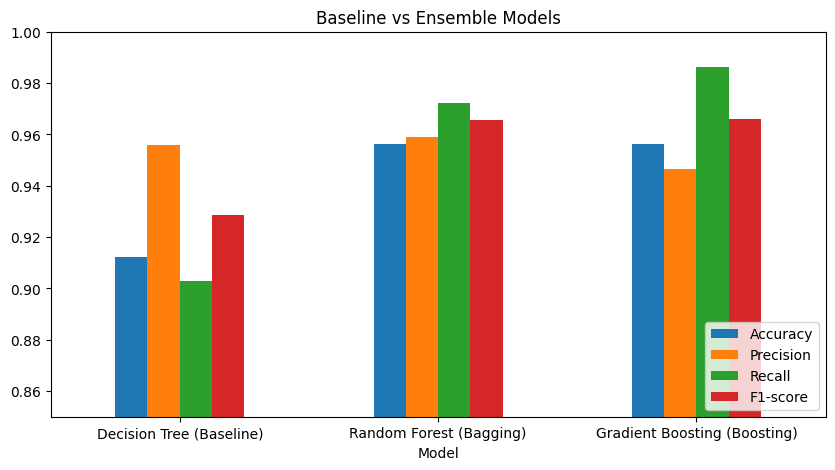

In [5]:
results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", ylim=(0.85, 1.0), rot=0, figsize=(10, 5))
plt.title("Baseline vs Ensemble Models")
plt.legend(loc="lower right")
plt.show()

## Effect of number of trees in Random Forest

In [6]:
for n in [1, 5, 10, 50, 100, 200]:
    rf = RandomForestClassifier(n_estimators=n, random_state=42)
    rf.fit(X_train, y_train)
    print(f"Trees = {n:3d}  ->  Accuracy = {accuracy_score(y_test, rf.predict(X_test)):.4f}")

Trees =   1  ->  Accuracy = 0.9474
Trees =   5  ->  Accuracy = 0.9386
Trees =  10  ->  Accuracy = 0.9386
Trees =  50  ->  Accuracy = 0.9561


Trees = 100  ->  Accuracy = 0.9561


Trees = 200  ->  Accuracy = 0.9561


## Top 10 important features (Random Forest)

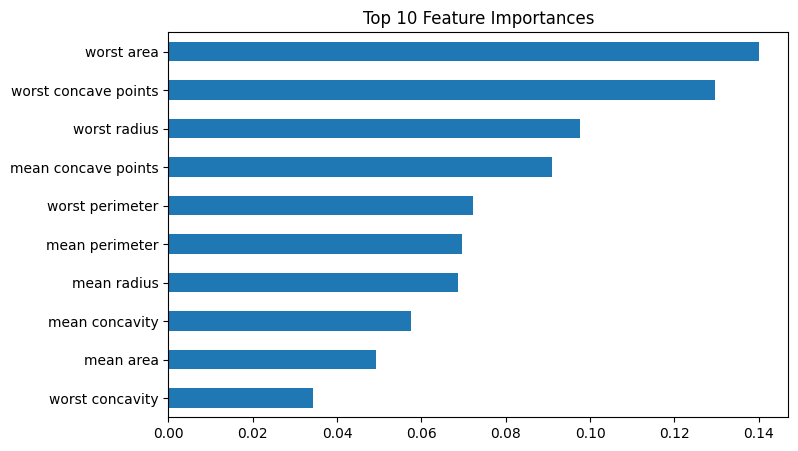

In [7]:
rf = models["Random Forest (Bagging)"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

importance.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Feature Importances")
plt.show()

## Conclusion
The single Decision Tree (baseline) gets ≈91% accuracy. **Random Forest and Gradient Boosting both reach ≈96%**, because combining many trees reduces errors: bagging (Random Forest) reduces variance, and boosting reduces bias by fixing previous mistakes. The cost is longer training time and less interpretability.